# 06 — Explore the REF Python API together

This is a workshop notebook. Run **one cell at a time**. Each section adds one
small piece of code, shows the result, and suggests a point to discuss before
moving on. It follows the same CMIP7 ACCESS-ESM1-6 diagnostic as the dashboard tour.

We will discover a diagnostic, select a model run, open a map and two other
figures, then use the numbers behind the figures to compare three models.

**What you need:** an internet connection and the environment in the
[README](../README.md). The cells query the live public REF API.

## 1 / Connect

Start by creating a client. This only sets up the connection; the next cell
makes the first request.

**Pause and discuss:** What is the difference between creating a client and
asking it for data?

In [1]:
from ref_tutorials import get_client

client = get_client()
print("Client ready for the public REF API")

Client ready for the public REF API


## 2 / Find the analysis

The REF calls each scientific analysis a **diagnostic**. Ask the API for its
diagnostic list, then pick the evaporation-minus-precipitation analysis used
in the dashboard tour.

In [2]:
from climate_ref_client.api.diagnostics import diagnostics_list

diagnostics = diagnostics_list.sync(client=client).data
print(f"Available diagnostics: {len(diagnostics)}")

Available diagnostics: 47


In [3]:
diagnostic = next(d for d in diagnostics if d.provider.slug == "ilamb" and d.slug == "emp-gleamgpcp2.3")
print(diagnostic.name)

Evaporation minus Precipitation (GLEAM/GPCP)


## 3 / Keep CMIP7 results

One diagnostic can have many **execution groups**. Each group is a selection
of model and reference data. `mip_era="CMIP7"` is the same kind of filter you
would use in the dashboard.

**Pause and discuss:** Try removing the `mip_era` argument. What changes?

In [4]:
from climate_ref_client.api.diagnostics import diagnostics_list_execution_groups

response = diagnostics_list_execution_groups.sync(
    diagnostic.provider.slug,
    diagnostic.slug,
    mip_era="CMIP7",
    client=client,
)
groups = response.data
print(f"CMIP7 groups: {len(groups)}")

CMIP7 groups: 135


## 4 / Choose ACCESS-ESM1-6

The group selectors contain the dashboard's model, experiment, and ensemble
member fields. We first unpack them, then filter for ACCESS-ESM1-6 `esm-hist`.

In [5]:
def cmip7_selectors(group):
    return dict(group.selectors.to_dict().get("cmip7", []))


print(cmip7_selectors(groups[0]))

{'experiment_id': 'esm-hist', 'grid_label': 'g110', 'source_id': 'UKESM1-3-LL', 'variant_label': 'r1i1p1f1'}


In [6]:
access_groups = [
    group
    for group in groups
    if cmip7_selectors(group).get("source_id") == "ACCESS-ESM1-6"
    and cmip7_selectors(group).get("experiment_id") == "esm-hist"
]
print(f"ACCESS-ESM1-6 esm-hist groups: {len(access_groups)}")

ACCESS-ESM1-6 esm-hist groups: 30


A model may have several ensemble members. Choose one whose latest
successful run actually has output files.

**Pause and discuss:** What does the `variant_label` tell us?

In [7]:
from ref_tutorials import latest_successful_execution

access_group = next(
    group
    for group in access_groups
    if (run := latest_successful_execution(group)) is not None and run.outputs
)
access_run = latest_successful_execution(access_group)
print(cmip7_selectors(access_group))

{'experiment_id': 'esm-hist', 'grid_label': 'g115', 'source_id': 'ACCESS-ESM1-6', 'variant_label': 'r24i1p1f1'}


## 5 / Inspect the files

A successful run can publish plots, data files, and an HTML page. The API
gives each file a type, a filename, and a URL.

In [8]:
from collections import Counter

Counter(item.output_type.value for item in access_run.outputs)

Counter({'plot': 26, 'data': 3, 'html': 1})

In [9]:
plots = [item for item in access_run.outputs if item.output_type.value == "plot"]
[(item.filename, item.url) for item in plots[:3]]

[('ACCESS-ESM1-6_global_bias.png',
  'https://api.climate-ref.org/api/v1/results/2416777'),
 ('ACCESS-ESM1-6_global_biasscore.png',
  'https://api.climate-ref.org/api/v1/results/2416778'),
 ('ACCESS-ESM1-6_global_cycle.png',
  'https://api.climate-ref.org/api/v1/results/2416779')]

## 6 / Download and display a map

The URL is enough to retrieve a figure. The global bias map compares
ACCESS-ESM1-6 with a reference combining GLEAM evapotranspiration and GPCP
precipitation.

**Pause and discuss:** The map is a ready-made REF output. Which line of code
actually downloads it?

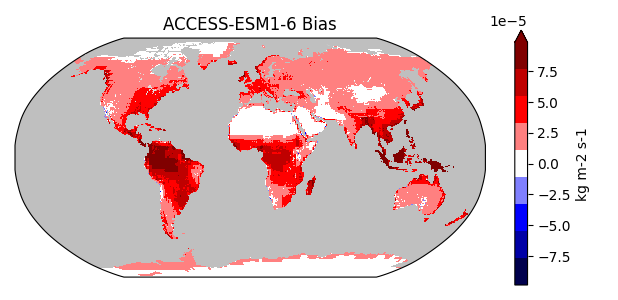

In [10]:
import requests
from IPython.display import Image, display

map_output = next(item for item in plots if item.filename.endswith("_global_bias.png"))
response = requests.get(map_output.url, timeout=60)
response.raise_for_status()
display(Image(data=response.content, width=650))

## 7 / Reuse the pattern

The map worked. We can turn those same steps into a small function, then
change only the filename suffix to see another plot.

In [11]:
def show_plot(suffix):
    output = next(item for item in plots if item.filename.endswith(suffix))
    response = requests.get(output.url, timeout=60)
    response.raise_for_status()
    display(Image(data=response.content, width=650))

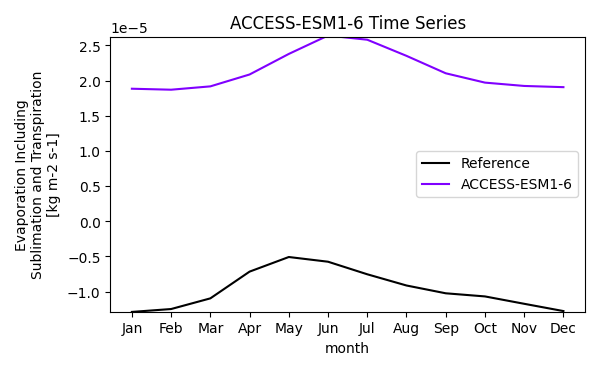

In [12]:
show_plot("_global_cycle.png")

The Taylor diagram is retrieved in exactly the same way. Its position shows
aspects of spatial pattern agreement with the reference.

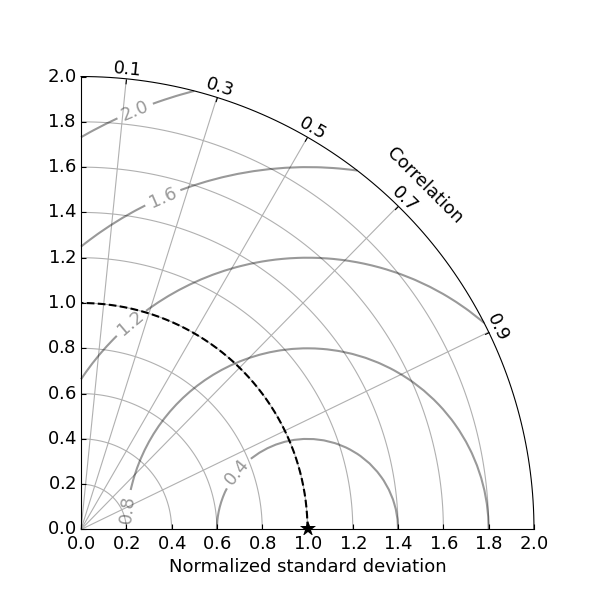

In [13]:
show_plot("_global_taylor.png")

## 8 / Read the numbers

Figures are useful for a quick look. The REF also publishes **metric values**
that we can inspect or use in our own analysis. Ask for the scalar values
from this exact run, then turn them into a pandas table.

In [14]:
from climate_ref_client.api.executions import executions_list_metric_values
from climate_ref_client.models.metric_value_type import MetricValueType

metric_response = executions_list_metric_values.sync(
    str(access_group.id),
    execution_id=str(access_run.id),
    value_type=MetricValueType.SCALAR,
    limit=100,
    with_facets=False,
    client=client,
)
print(f"Scalar values: {len(metric_response.data)}")

Scalar values: 20


In [15]:
from ref_tutorials import metric_values_to_dataframe

metrics = metric_values_to_dataframe(metric_response.data)
global_metrics = metrics.loc[metrics["region"] == "global"]
display(global_metrics[["metric", "statistic", "value"]].reset_index(drop=True))

,metric,statistic,value
0,Annual Cycle,Phase Shift,-0.120913
1,Annual Cycle,Seasonal Cycle Score,0.615758
2,Bias,Bias,0.000030
3,Bias,Bias Score,0.218127
4,Bias,Period Mean,0.000021
5,RMSE,RMSE,0.000037
6,RMSE,RMSE Score,0.313550
7,Spatial Distribution,Correlation,-0.427624
8,Spatial Distribution,Normalized Standard Deviation,1.443001
9,Spatial Distribution,Spatial Distribution Score,0.250904


## 9 / Start with one model

Select the global **Bias Score**. This number belongs to this diagnostic,
reference, experiment, and ensemble member. It is not an overall model ranking.

In [16]:
import pandas as pd

bias_score = global_metrics.loc[global_metrics["statistic"] == "Bias Score", "value"].iloc[0]
comparison = pd.DataFrame(
    [
        {
            "model": "ACCESS-ESM1-6",
            "member": cmip7_selectors(access_group)["variant_label"],
            "bias_score": bias_score,
        }
    ]
)
display(comparison)

,model,member,bias_score
0,ACCESS-ESM1-6,r24i1p1f1,0.218127


## 10 / Add another model

We have used the same two steps twice: find a successful group and read its
Bias Score. Name those steps so we can reuse them for other models.

In [17]:
def group_for_model(name):
    return next(
        group
        for group in groups
        if cmip7_selectors(group).get("source_id") == name
        and cmip7_selectors(group).get("experiment_id") == "esm-hist"
        and (run := latest_successful_execution(group)) is not None
        and run.outputs
    )

In [18]:
def bias_score_for_group(group):
    run = latest_successful_execution(group)
    response = executions_list_metric_values.sync(
        str(group.id),
        execution_id=str(run.id),
        value_type=MetricValueType.SCALAR,
        limit=100,
        with_facets=False,
        client=client,
    )
    values = metric_values_to_dataframe(response.data)
    match = values.loc[
        (values["region"] == "global") & (values["statistic"] == "Bias Score"),
        "value",
    ]
    return float(match.iloc[0])

In [19]:
canesm_group = group_for_model("CanESM5-1")
comparison.loc[len(comparison)] = {
    "model": "CanESM5-1",
    "member": cmip7_selectors(canesm_group)["variant_label"],
    "bias_score": bias_score_for_group(canesm_group),
}
display(comparison)

,model,member,bias_score
0,ACCESS-ESM1-6,r24i1p1f1,0.218127
1,CanESM5-1,r1i1p2f1,0.233196


## 11 / Add a third and make a figure

One more model uses the same pattern. From here, we are working with an
ordinary pandas table, so a familiar matplotlib plot is enough.

**Pause and discuss:** Which parts of this notebook would you change to
explore a different REF diagnostic?

In [20]:
ukesm_group = group_for_model("UKESM1-3-LL")
comparison.loc[len(comparison)] = {
    "model": "UKESM1-3-LL",
    "member": cmip7_selectors(ukesm_group)["variant_label"],
    "bias_score": bias_score_for_group(ukesm_group),
}
display(comparison)

,model,member,bias_score
0,ACCESS-ESM1-6,r24i1p1f1,0.218127
1,CanESM5-1,r1i1p2f1,0.233196
2,UKESM1-3-LL,r1i1p1f1,0.254746


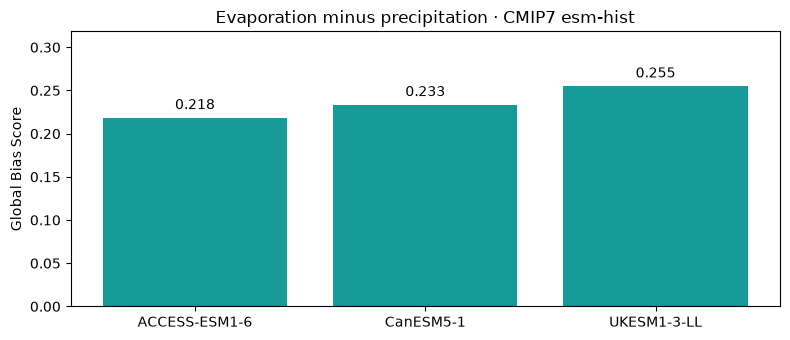

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(comparison["model"], comparison["bias_score"], color="#179b98")
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set_ylabel("Global Bias Score")
ax.set_title("Evaporation minus precipitation · CMIP7 esm-hist")
ax.set_ylim(0, max(comparison["bias_score"]) * 1.25)
fig.tight_layout()
plt.show()
plt.close(fig)

## Keep exploring

We moved from a dashboard-style selection to downloaded figures, numeric
results, and our own plot. Try changing the model, experiment, or diagnostic.
The available results change as the REF processes more data.

- [02 — Querying the REF API](02-querying-the-api.ipynb) goes deeper into files and metric values.
- [03 — Build a figure one model at a time](03-publication-figure.ipynb) works with temperature time series.
- [05 — ECS and temperature](05-ecs-temperature-figure.ipynb) combines two diagnostics.